## ParFlow-CLM Water Balance Exercise
This notebook runs a single column ParFlow-CLM simulation for one day (see figure below) and calcualtes a water blance.

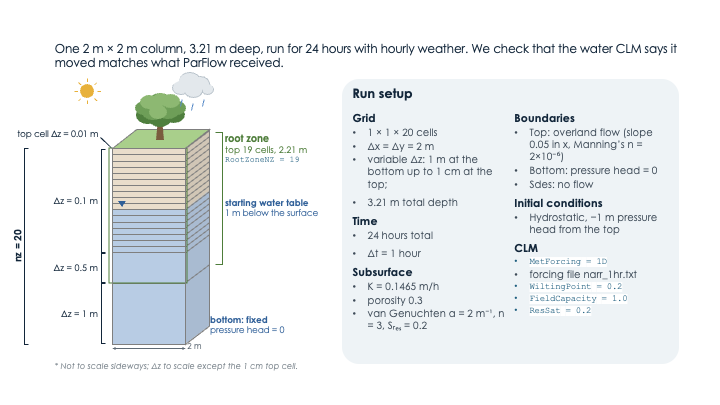

### Setup
Copy this notebook along with the inputs and forcing folders into your my work folder (you can also just copy all of the activity 4 folder in there if that's easier)


### Activities
- First run the baseline case to familiarize yourself with the setup
- Then experiment with changing the following: 
    - The lenght of the simulations
    - The water table depth in the run 
    - The number of layers that ParFlow and CLM are coupled over
    - The landcover type
    - One of the parameters for the landcover type you chose
    

*Remember - try to to overlaod your codespace too much so delete runs as needed if you are getting a ton of outputs*

## Part1: Run ParFlow-CLM 

### 1.0 Importing packages

In [1]:
import os
import shutil
from pathlib import Path
from glob import glob


import matplotlib.pyplot as plt
import numpy as np
import netCDF4 as nc
import xarray as xr
import time as timer
import pandas as pd


import parflow as pf
from parflow import Run
from parflow.tools.fs import mkdir, cp, chdir, get_absolute_path, rm, exists
import parflow.tools.hydrology as hydro

### 1.1 Setting up run name and directory

In [ ]:
#Set run name (CHANGE THis for later runs)
pf_runname = "Baseline_Col" 


# set up the run directory
folder_name = "single_column_runs"
base = os.path.join(os.getcwd(), folder_name, pf_runname)
mkdir(base)
print(base)


# copy CLM files into your run directory
cp('inputs/drv_clmin.dat', os.path.join(base, 'drv_clmin.dat'))
cp('inputs/drv_vegm.dat', os.path.join(base, 'drv_vegm.dat'))
cp('inputs/drv_vegp.dat', os.path.join(base, 'drv_vegp.dat'))


# Create the ParFlow run object
PFCLM_SC = Run(pf_runname)

/workspaces/ParFlow_CUAHSI_VU/Activity4_SingleColum_CLM/single_column_runs/Forest_Col


### 1.2 Setting up the single column run

Pulling out some variables that you may want to change in subsequent runs here. Feel free to add others as you do your activities

In [6]:
## run only for 24 hours for the water balance example
stopt = 24
#stopt = 8760

# depth of water table below the surface in meters 
# (will be use for the lower BC)
wtd = 5  

# Which file to use for forcing data.  Options are:
# narr_1hr.txt, forcing_1.txt, pumphouse_forcing_wy17_wy19.txt
forcing_file_name = "narr_1hr.txt"


Here is the full PF setup. Note that the variables set above get used to set key names below

In [7]:
#-----------------------------------------------------------------------------
# File input version number
#-----------------------------------------------------------------------------
PFCLM_SC.FileVersion = 4

#-----------------------------------------------------------------------------
# Process Topology
#-----------------------------------------------------------------------------

PFCLM_SC.Process.Topology.P = 1
PFCLM_SC.Process.Topology.Q = 1
PFCLM_SC.Process.Topology.R = 1

#-----------------------------------------------------------------------------
# Computational Grid
#-----------------------------------------------------------------------------
PFCLM_SC.ComputationalGrid.Lower.X = 0.0
PFCLM_SC.ComputationalGrid.Lower.Y = 0.0
PFCLM_SC.ComputationalGrid.Lower.Z = 0.0

PFCLM_SC.ComputationalGrid.DX      = 2.0
PFCLM_SC.ComputationalGrid.DY      = 2.0
PFCLM_SC.ComputationalGrid.DZ      = 0.1

PFCLM_SC.ComputationalGrid.NX      = 1
PFCLM_SC.ComputationalGrid.NY      = 1
PFCLM_SC.ComputationalGrid.NZ      = 20

#-----------------------------------------------------------------------------
# The Names of the GeomInputs
#-----------------------------------------------------------------------------
PFCLM_SC.GeomInput.Names = 'domain_input'

#-----------------------------------------------------------------------------
# Domain Geometry Input
#-----------------------------------------------------------------------------
PFCLM_SC.GeomInput.domain_input.InputType = 'Box'
PFCLM_SC.GeomInput.domain_input.GeomName  = 'domain'

#-----------------------------------------------------------------------------
# Domain Geometry
#-----------------------------------------------------------------------------
PFCLM_SC.Geom.domain.Lower.X = 0.0
PFCLM_SC.Geom.domain.Lower.Y = 0.0
PFCLM_SC.Geom.domain.Lower.Z = 0.0

PFCLM_SC.Geom.domain.Upper.X = 2.0
PFCLM_SC.Geom.domain.Upper.Y = 2.0
PFCLM_SC.Geom.domain.Upper.Z = 2.0

PFCLM_SC.Geom.domain.Patches = 'x_lower x_upper y_lower y_upper z_lower z_upper'


#--------------------------------------------
# variable dz assignments
#------------------------------------------

PFCLM_SC.Solver.Nonlinear.VariableDz = True
PFCLM_SC.dzScale.GeomNames           = 'domain'
PFCLM_SC.dzScale.Type                = 'nzList'
PFCLM_SC.dzScale.nzListNumber        = 20

# cells start at the bottom (0) and moves up to the top
# domain is 3.21 m thick, root zone is down to 19 cells 
# so the root zone is 2.21 m thick
PFCLM_SC.Cell._0.dzScale.Value  = 10.0   # first cell is 10*0.1 1m thick
PFCLM_SC.Cell._1.dzScale.Value  = 5.0    # next cell is 5*0.1 50 cm thick
PFCLM_SC.Cell._2.dzScale.Value  = 1.0   
PFCLM_SC.Cell._3.dzScale.Value  = 1.0
PFCLM_SC.Cell._4.dzScale.Value  = 1.0
PFCLM_SC.Cell._5.dzScale.Value  = 1.0
PFCLM_SC.Cell._6.dzScale.Value  = 1.0
PFCLM_SC.Cell._7.dzScale.Value  = 1.0
PFCLM_SC.Cell._8.dzScale.Value  = 1.0
PFCLM_SC.Cell._9.dzScale.Value  = 1.0
PFCLM_SC.Cell._10.dzScale.Value = 1.0
PFCLM_SC.Cell._11.dzScale.Value = 1.0
PFCLM_SC.Cell._12.dzScale.Value = 1.0
PFCLM_SC.Cell._13.dzScale.Value = 1.0
PFCLM_SC.Cell._14.dzScale.Value = 1.0
PFCLM_SC.Cell._15.dzScale.Value = 1.0
PFCLM_SC.Cell._16.dzScale.Value = 1.0
PFCLM_SC.Cell._17.dzScale.Value = 1.0
PFCLM_SC.Cell._18.dzScale.Value = 1.0
PFCLM_SC.Cell._19.dzScale.Value = 0.1   #0.1* 0.1 = 0.01  1 cm top layer

#-----------------------------------------------------------------------------
# Perm
#-----------------------------------------------------------------------------
PFCLM_SC.Geom.Perm.Names              = 'domain'
PFCLM_SC.Geom.domain.Perm.Type        = 'Constant'
PFCLM_SC.Geom.domain.Perm.Value       = 0.001465
PFCLM_SC.Geom.domain.Perm.Value       = 0.1465

PFCLM_SC.Perm.TensorType              = 'TensorByGeom'
PFCLM_SC.Geom.Perm.TensorByGeom.Names = 'domain'
PFCLM_SC.Geom.domain.Perm.TensorValX  = 1.0
PFCLM_SC.Geom.domain.Perm.TensorValY  = 1.0
PFCLM_SC.Geom.domain.Perm.TensorValZ  = 1.0

#-----------------------------------------------------------------------------
# Specific Storage
#-----------------------------------------------------------------------------

PFCLM_SC.SpecificStorage.Type              = 'Constant'
PFCLM_SC.SpecificStorage.GeomNames         = 'domain'
PFCLM_SC.Geom.domain.SpecificStorage.Value = 1.0e-4

#-----------------------------------------------------------------------------
# Phases
#-----------------------------------------------------------------------------

PFCLM_SC.Phase.Names = 'water'

PFCLM_SC.Phase.water.Density.Type     = 'Constant'
PFCLM_SC.Phase.water.Density.Value    = 1.0

PFCLM_SC.Phase.water.Viscosity.Type   = 'Constant'
PFCLM_SC.Phase.water.Viscosity.Value  = 1.0

#-----------------------------------------------------------------------------
# Contaminants
#-----------------------------------------------------------------------------
PFCLM_SC.Contaminants.Names = ''


#-----------------------------------------------------------------------------
# Gravity
#-----------------------------------------------------------------------------

PFCLM_SC.Gravity = 1.0

#-----------------------------------------------------------------------------
# Setup timing info
#-----------------------------------------------------------------------------

PFCLM_SC.TimingInfo.BaseUnit     = 1.0
PFCLM_SC.TimingInfo.StartCount   = 0
PFCLM_SC.TimingInfo.StartTime    = 0.0
PFCLM_SC.TimingInfo.StopTime     = stopt
PFCLM_SC.TimingInfo.DumpInterval = 1.0
PFCLM_SC.TimeStep.Type           = 'Constant'
PFCLM_SC.TimeStep.Value          = 1.0


#-----------------------------------------------------------------------------
# Porosity
#-----------------------------------------------------------------------------

PFCLM_SC.Geom.Porosity.GeomNames    = 'domain'
PFCLM_SC.Geom.domain.Porosity.Type  = 'Constant'
PFCLM_SC.Geom.domain.Porosity.Value = 0.3

#-----------------------------------------------------------------------------
# Domain
#-----------------------------------------------------------------------------
PFCLM_SC.Domain.GeomName = 'domain'

#-----------------------------------------------------------------------------
# Mobility
#-----------------------------------------------------------------------------
PFCLM_SC.Phase.water.Mobility.Type  = 'Constant'
PFCLM_SC.Phase.water.Mobility.Value = 1.0

#-----------------------------------------------------------------------------
# Relative Permeability
#-----------------------------------------------------------------------------

PFCLM_SC.Phase.RelPerm.Type        = 'VanGenuchten'
PFCLM_SC.Phase.RelPerm.GeomNames   = 'domain'

PFCLM_SC.Geom.domain.RelPerm.Alpha = 2.0
PFCLM_SC.Geom.domain.RelPerm.N     = 2.0

#---------------------------------------------------------
# Saturation
#---------------------------------------------------------

PFCLM_SC.Phase.Saturation.Type        = 'VanGenuchten'
PFCLM_SC.Phase.Saturation.GeomNames   = 'domain'

PFCLM_SC.Geom.domain.Saturation.Alpha = 2.0
PFCLM_SC.Geom.domain.Saturation.N     = 3.0
PFCLM_SC.Geom.domain.Saturation.SRes  = 0.2
PFCLM_SC.Geom.domain.Saturation.SSat  = 1.0

#-----------------------------------------------------------------------------
# Wells
#-----------------------------------------------------------------------------
PFCLM_SC.Wells.Names = ''


#-----------------------------------------------------------------------------
# Time Cycles
#-----------------------------------------------------------------------------
PFCLM_SC.Cycle.Names = 'constant'
PFCLM_SC.Cycle.constant.Names = 'alltime'
PFCLM_SC.Cycle.constant.alltime.Length = 1
PFCLM_SC.Cycle.constant.Repeat = -1

#-----------------------------------------------------------------------------
# Boundary Conditions: Pressure
#-----------------------------------------------------------------------------
PFCLM_SC.BCPressure.PatchNames = 'x_lower x_upper y_lower y_upper z_lower z_upper'

PFCLM_SC.Patch.x_lower.BCPressure.Type          = 'FluxConst'
PFCLM_SC.Patch.x_lower.BCPressure.Cycle         = 'constant'
PFCLM_SC.Patch.x_lower.BCPressure.alltime.Value = 0.0

PFCLM_SC.Patch.y_lower.BCPressure.Type          = 'FluxConst'
PFCLM_SC.Patch.y_lower.BCPressure.Cycle         = 'constant'
PFCLM_SC.Patch.y_lower.BCPressure.alltime.Value = 0.0

#PFCLM_SC.Patch.z_lower.BCPressure.Type = 'FluxConst'
PFCLM_SC.Patch.z_lower.BCPressure.Type          = 'DirEquilRefPatch'
PFCLM_SC.Patch.z_lower.BCPressure.RefGeom       = 'domain'
PFCLM_SC.Patch.z_lower.BCPressure.RefPatch      = 'z_lower'
PFCLM_SC.Patch.z_lower.BCPressure.Cycle         = 'constant'
PFCLM_SC.Patch.z_lower.BCPressure.alltime.Value = max(3.21-wtd, 0.0)

PFCLM_SC.Patch.x_upper.BCPressure.Type          = 'FluxConst'
PFCLM_SC.Patch.x_upper.BCPressure.Cycle         = 'constant'
PFCLM_SC.Patch.x_upper.BCPressure.alltime.Value = 0.0

PFCLM_SC.Patch.y_upper.BCPressure.Type          = 'FluxConst'
PFCLM_SC.Patch.y_upper.BCPressure.Cycle         = 'constant'
PFCLM_SC.Patch.y_upper.BCPressure.alltime.Value = 0.0

PFCLM_SC.Patch.z_upper.BCPressure.Type          = 'OverlandFlow'
PFCLM_SC.Patch.z_upper.BCPressure.Cycle         = 'constant'
PFCLM_SC.Patch.z_upper.BCPressure.alltime.Value = 0.0

#---------------------------------------------------------
# Topo slopes in x-direction
#---------------------------------------------------------

PFCLM_SC.TopoSlopesX.Type              = 'Constant'
PFCLM_SC.TopoSlopesX.GeomNames         = 'domain'
PFCLM_SC.TopoSlopesX.Geom.domain.Value = 0.05

#---------------------------------------------------------
# Topo slopes in y-direction
#---------------------------------------------------------

PFCLM_SC.TopoSlopesY.Type              = 'Constant'
PFCLM_SC.TopoSlopesY.GeomNames         = 'domain'
PFCLM_SC.TopoSlopesY.Geom.domain.Value = 0.00

#---------------------------------------------------------
# Mannings coefficient
#---------------------------------------------------------

PFCLM_SC.Mannings.Type               = 'Constant'
PFCLM_SC.Mannings.GeomNames          = 'domain'
PFCLM_SC.Mannings.Geom.domain.Value  = 2.e-6

#-----------------------------------------------------------------------------
# Phase sources:
#-----------------------------------------------------------------------------

PFCLM_SC.PhaseSources.water.Type              = 'Constant'
PFCLM_SC.PhaseSources.water.GeomNames         = 'domain'
PFCLM_SC.PhaseSources.water.Geom.domain.Value = 0.0

#-----------------------------------------------------------------------------
# Exact solution specification for error calculations
#-----------------------------------------------------------------------------

PFCLM_SC.KnownSolution = 'NoKnownSolution'

#-----------------------------------------------------------------------------
# Set solver parameters
#-----------------------------------------------------------------------------

PFCLM_SC.Solver         = 'Richards'
PFCLM_SC.Solver.MaxIter = 9000

PFCLM_SC.Solver.Nonlinear.MaxIter           = 100
PFCLM_SC.Solver.Nonlinear.ResidualTol       = 1e-5
PFCLM_SC.Solver.Nonlinear.EtaChoice         = 'Walker1'
PFCLM_SC.Solver.Nonlinear.EtaValue          = 0.01
PFCLM_SC.Solver.Nonlinear.UseJacobian       = False
PFCLM_SC.Solver.Nonlinear.DerivativeEpsilon = 1e-12
PFCLM_SC.Solver.Nonlinear.StepTol           = 1e-30
PFCLM_SC.Solver.Nonlinear.Globalization     = 'LineSearch'
PFCLM_SC.Solver.Linear.KrylovDimension      = 100
PFCLM_SC.Solver.Linear.MaxRestarts          = 5
PFCLM_SC.Solver.Linear.Preconditioner       = 'PFMG'
PFCLM_SC.Solver.PrintSubsurf                = False
PFCLM_SC.Solver.Drop                        = 1E-20
PFCLM_SC.Solver.AbsTol                      = 1E-9

#Writing output options for ParFlow
write_pfb = True  #only PFB output for water balance example
#  PFB  no SILO
PFCLM_SC.Solver.PrintSubsurfData         = write_pfb
PFCLM_SC.Solver.PrintPressure            = write_pfb
PFCLM_SC.Solver.PrintSaturation          = write_pfb
PFCLM_SC.Solver.PrintCLM                 = write_pfb
PFCLM_SC.Solver.PrintMask                = write_pfb
PFCLM_SC.Solver.PrintSpecificStorage     = write_pfb
PFCLM_SC.Solver.PrintEvapTrans           = write_pfb

PFCLM_SC.Solver.WriteSiloMannings        = False
PFCLM_SC.Solver.WriteSiloMask            = False
PFCLM_SC.Solver.WriteSiloSlopes          = False
PFCLM_SC.Solver.WriteSiloSaturation      = False

#write output in NetCDF
write_netcdf = False
#PFCLM_SC.NetCDF.NumStepsPerFile          = 240
PFCLM_SC.NetCDF.WritePressure            = write_netcdf
PFCLM_SC.NetCDF.WriteSubsurface          = False
PFCLM_SC.NetCDF.WriteSaturation          = write_netcdf
PFCLM_SC.NetCDF.WriteCLM                 = write_netcdf
#PFCLM_SC.NetCDF.CLMNumStepsPerFile       = 240


#---------------------------------------------------
# LSM / CLM options
#---------------------------------------------------

# set LSM options to CLM
PFCLM_SC.Solver.LSM              = 'CLM'
# specify type of forcing, file name and location
PFCLM_SC.Solver.CLM.MetForcing   = '1D'
PFCLM_SC.Solver.CLM.MetFileName = forcing_file_name
PFCLM_SC.Solver.CLM.MetFilePath  = '../../forcing'


# Set CLM Plant Water Use Parameters
PFCLM_SC.Solver.CLM.EvapBeta       = 'Linear'
PFCLM_SC.Solver.CLM.VegWaterStress = 'Saturation'
PFCLM_SC.Solver.CLM.ResSat         = 0.2
PFCLM_SC.Solver.CLM.WiltingPoint   = 0.2
PFCLM_SC.Solver.CLM.FieldCapacity  = 1.00
PFCLM_SC.Solver.CLM.IrrigationType = 'none'
PFCLM_SC.Solver.CLM.RootZoneNZ     =  19
PFCLM_SC.Solver.CLM.SoiLayer       =  15

#Writing output options for CLM
#  no SILO, no native CLM logs
PFCLM_SC.Solver.PrintLSMSink        = False
PFCLM_SC.Solver.CLM.CLMDumpInterval = 1
PFCLM_SC.Solver.CLM.CLMFileDir      = 'output/'
PFCLM_SC.Solver.CLM.BinaryOutDir    = False
PFCLM_SC.Solver.CLM.IstepStart      = 1
PFCLM_SC.Solver.WriteCLMBinary      = False
PFCLM_SC.Solver.WriteSiloCLM        = False
PFCLM_SC.Solver.CLM.WriteLogs       = False
PFCLM_SC.Solver.CLM.WriteLastRST    = True
PFCLM_SC.Solver.CLM.DailyRST        = False
PFCLM_SC.Solver.CLM.SingleFile      = True
#PFCLM_SC.NetCDF.Compression         = True
#PFCLM_SC.NetCDF.ROMIOhints='romio.hints'
#PFCLM_SC.NetCDF.NodeLevelIO         = True

#---------------------------------------------------
# Initial conditions: water pressure
#---------------------------------------------------

PFCLM_SC.ICPressure.Type                 = 'HydroStaticPatch'
PFCLM_SC.ICPressure.GeomNames            = 'domain'
PFCLM_SC.Geom.domain.ICPressure.Value    = -1.0
PFCLM_SC.Geom.domain.ICPressure.RefGeom  = 'domain'
PFCLM_SC.Geom.domain.ICPressure.RefPatch = 'z_upper'

#-----------------------------------------------------------------------------
# Run ParFlow 
#-----------------------------------------------------------------------------

PFCLM_SC.run(working_directory=base)


: Field _run_file is not part of the expected schema <class 'parflow.tools.core.Run'>

# ==============================================================================
# ParFlow directory
#  - /opt/parflow/
# ParFlow version
#  - 3.15.0
# Working directory
#  - /workspaces/ParFlow_CUAHSI_VU/Activity4_SingleColum_CLM/single_column_runs/Forest_Col
# ParFlow database
#  - Forest_Col.pfidb
# ==============================================================================


# ==============================================================================
# ParFlow ran successfully
# ==============================================================================



## Part 2: Plotting and water balance calculations for a single run
The next cell in this notebook conducts a water balance with CLM output variables and the `EvapTrans` vector output by ParFlow.  This vector is an output of what CLM passes to ParFlow every timestep and can be used for diagnostics.  This vector can be used (as we did in earlier notebooks) to conduct a water balance of ParFlow but in this case we are just comparing the CLM output variables to the `EvapTrans` vector.   

### 2.1 Set names and load in the ParFlow run

In [10]:
# Runname to plot
#pf_runname = "Forest_Col"
#folder_name = 'single_column_runs' 
path = os.path.join(os.getcwd(), folder_name, pf_runname)
forcing_path = os.path.join(os.getcwd(), 'forcing')
print(path)


# load in the run information from the PFIDB file
run = Run.from_definition(f'{path}/{pf_runname}.pfidb')
data = run.data_accessor
nx = data.shape[2]
ny = data.shape[1]
nz = data.shape[0]
dx = data.dx
dy = data.dy
dz = data.dz

# intialize data and time arrays
data    = np.zeros([8,8760])
time    = np.zeros([8760])

/workspaces/ParFlow_CUAHSI_VU/Activity4_SingleColum_CLM/single_column_runs/Forest_Col
  - qflx_tran_vegm


### 2.2 Load in the atmospheric forcings into a pandas dataframe
- DSWR:  Downward Visible or Short-Wave radiation [W/m2]
- DLWR:  Downward Infa-Red or Long-Wave radiation [W/m2]
- APCP:  Precipitation rate [mm/s]
- Temp:  Air temperature [K]
- UGRD:  West-to-East or U-component of wind [m/s]
- VGRD:  South-to-North or V-component of wind [m/s]
- Press: Atmospheric Pressure [pa]
- SPFH:  Water-vapor specific humidity [kg/kg]


In [11]:
# load the forcing file into a Pandas dataframe
# we could load this file directly, as is shown in the commented-out line, but we can also
# use the key database and load it dynamically as shown
#file = path_forcing+"/narr_1hr.txt"
file = forcing_path+'/'+run.Solver.CLM.MetFileName

# 1D forcing files are text columns not technically CSVs but this is an easy 
# way to load
forcing_df = pd.read_csv(file,sep='\s{2,}',header=None,engine='python')
# add PF-CLM variable names and units 
forcing_df.columns = ["DSWR [W/m2]", "DLWR [W/m2]", "APCP [mm/s]", "Temp [K]", "UGRD [m/s]","VGRD [m/s]","Press [pa]","SPFH [kg/kg]"]


### 2.3 Read in the CLM outputs

CLM ouptuts are saved in the <run_name>_output.<file number>.C.pfb files. 
The containe the following variables in the following order: 
- 0 eflx_lh_tot:  total latent heat flux (Wm-2)  
- 1 eflx_lwrad_out: total upward LW radiation (Wm-2)  
- 2 eflx_sh_tot: total sensible heat flux (Wm-2)  
- 3 eflx_soil_grnd: ground heat flux (Wm-2)    
- 4 qflx_evap_tot: net veg. evaporation and transpiration and soil evaporation (mms-1)  
- 5 qflx_evap_grnd: ground evaporation (mms-1)   
- 6 qflx_evap_soi: soil evaporation (mms-1)   
- 7 qflx_evap_veg: vegetation evaporation (canopy) and transpiration (mms-1)   
- 8 qflx_tran_veg: transpiration (mms-1)  
- 9 qflx_infl: infiltration flux (mms-1)   
- 10 swe_out: SWE (mm)   
- 11 t_grnd: ground temperature (K)  
- 12 irrigation flux
- 13 - 24 Soil temperature by layer (K)

In [16]:
#  assemble files to be loaded as an entire sequence
files = sorted(glob(os.path.join(path, f"{pf_runname}.out.clm_output.*.C.pfb")))
CLM_data = pf.read_pfb_sequence(files)
## create data frame for CLM output ET vars
clm_output = pd.DataFrame({'T [mm/s]':CLM_data[:,8,0,0],
                           'Ebs [mm/s]':CLM_data[:,6,0,0],''
                           'Qflux infil [mm/s]':CLM_data[:,9,0,0],
                           'Qflux irrig [mm/s]':CLM_data[:,12,0,0],
                           'qflx_evap_grnd [mm/s]':CLM_data[:,5,0,0],
                           'qflx_evap_veg [mm/s]':CLM_data[:,7,0,0] })

### 2.4 Load in the evaptrans output from parflow
We are just using this for a comparison on the water balance. 
This is constructed in the coupling between PF and CLM as follows:
- The uppermost soil layer is assigned the infiltration flux (qflx_infl) + irrigation water applied - transpiration (qflx_tran_veg):
- Layers below this are assigned the transpiration X the root fraction.  


In [17]:
## assemble the evap trans files
files = sorted(glob(os.path.join(path, f"{pf_runname}.out.evaptrans.*.pfb")))
pf_EvapTrans = pf.read_pfb_sequence(files)

# set up an evap_trans array to hold the summed values for the evap trans output
evap_trans = np.zeros(24)
for i in range(24):
    evap_trans[i] = np.sum(pf_EvapTrans[i,:,0,0]*dz)*1000.*24  # to go from 1/h to m/h to mm/h to mm/day

### 2.5 Calcualte a water balance and plot
We will calculate this two waysL: 
1. using the forcings and the output of bare soil evap and Transpiration from CLM (Referred to as Balance)
2. using the qflux infil and the transpiration from CLM  (referred to as Balance 2)

In both cases we calcualte the residual compared to the total evaptrans flux that ParFlow Reports 

We will compare these two approaches below note that our precip input and the flux outputs are all in [mm/s] units.  We convert to mm/d for more friendly units


Table of water balance values:
 balance    balance2   evap_trans residual   residual2
 1.442e-01  1.442e-01  1.442e-01  0.000e+00  0.000e+00
-3.971e-01  1.133e-01 -3.971e-01 -5.551e-17  5.103e-01
-3.460e-01  7.113e-02 -3.460e-01  0.000e+00  4.171e-01
-2.149e-01  1.362e-01 -2.400e-01  2.514e-02  3.762e-01
-6.884e-02  2.180e-01 -1.212e-01  5.238e-02  3.392e-01
 7.099e-02  2.975e-01 -6.532e-03  7.752e-02  3.041e-01
 1.545e-01  3.376e-01  6.445e-02  9.009e-02  2.731e-01
 2.366e-01  3.773e-01  1.339e-01  1.027e-01  2.434e-01
 3.188e-01  4.186e-01  2.036e-01  1.152e-01  2.150e-01
 2.321e-01  3.386e-01  1.420e-01  9.009e-02  1.966e-01
 1.459e-01  2.594e-01  8.095e-02  6.495e-02  1.784e-01
 5.974e-02  1.806e-01  1.994e-02  3.981e-02  1.606e-01
-2.260e+00  1.194e-01 -2.288e+00  2.724e-02  2.407e+00
-3.973e+00  5.972e-02 -3.986e+00  1.257e-02  4.045e+00
-4.351e+00 -2.801e-04 -4.351e+00 -8.882e-16  4.351e+00
-3.440e+00 -3.855e-02 -3.440e+00 -4.441e-16  3.401e+00
-3.259e+00 -8.533e-02 -3.259e+00 

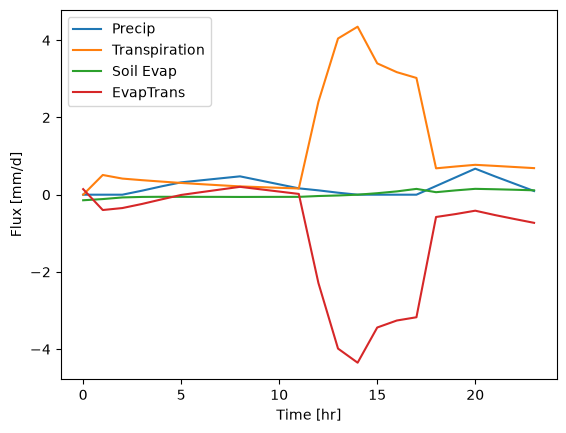

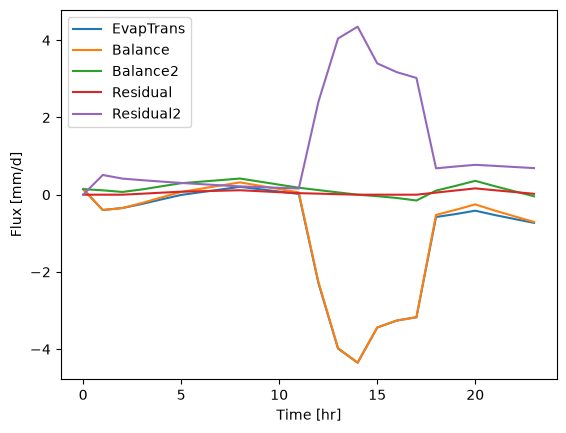

In [18]:
# calculate the water balance from CLM to PF
balance = forcing_df['APCP [mm/s]'].iloc[0:24]*(3600*24)- (clm_output['T [mm/s]'].apply(pd.to_numeric)*(3600*24) + clm_output['Ebs [mm/s]'].apply(pd.to_numeric)*(3600*24))
balance2 = (clm_output['Qflux irrig [mm/s]'].apply(pd.to_numeric)*(3600*24)+ clm_output['Qflux infil [mm/s]'].apply(pd.to_numeric)*(3600*24))

# calculate two residuals, checked against the evap_trans values, corresponding to balance and balance2 above 
residual = (balance - evap_trans)
residual2 = (balance2 - evap_trans)

# we make a table of the water balances and corresponding residuals
print()
print("Table of water balance values:")
print(" balance    balance2   evap_trans residual   residual2")
for i in range (stopt):
    print('% 5.3e % 5.3e % 5.3e % 5.3e % 5.3e' % (balance[i], balance2[i],evap_trans[i],residual[i],residual2[i]))


# Plot the inputs to this water balance calculation
plt.plot(forcing_df['APCP [mm/s]'].iloc[0:24]*(3600*24), label='Precip')  
plt.plot(clm_output['T [mm/s]']*(3600*24), label='Transpiration')  
plt.plot(clm_output['Ebs [mm/s]']*(3600*24), label='Soil Evap')  
plt.plot(evap_trans, label='EvapTrans') 
plt.xlabel('Time [hr]')  
plt.ylabel('Flux [mm/d]')  ## note that we converted the fluxes to mm/d
plt.legend()
plt.show()

# Plot the different forcing term calculations, Evap Trans, and the residuals
plt.plot(evap_trans, label='EvapTrans')  
plt.plot(balance, label='Balance')  
plt.plot(balance2, label='Balance2')  
plt.plot(residual, label='Residual')  
plt.plot(residual2, label='Residual2')  
plt.xlabel('Time [hr]')  
plt.ylabel('Flux [mm/d]')  
plt.legend()
plt.show()